# Libraries

In [ ]:
import json
import sys 
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from matplotlib.patches import Patch, Rectangle

ROOT = Path.cwd().resolve()
if ROOT.name.lower() == "notebooks":
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.ocr_loader import load_ocr

: 

# Data Paths

In [19]:
EDA_DIR = ROOT / "outputs/eda"
FIGURE_DIR = ROOT / "outputs/figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

answer_groups = pd.read_csv(EDA_DIR / "answer_groups.csv")
ocr_summary = pd.read_csv(EDA_DIR / "ocr.csv")

display(answer_groups.head())
display(ocr_summary)

,split,length_group,answers,percent
0,train,1 word,23977,42.618959
1,train,2-3 words,22554,40.089586
2,train,4-5 words,6818,12.118950
3,train,6-10 words,2599,4.619705
4,train,11-15 words,258,0.458593


,split,documents,ocr_files_found,total_ocr_words,mean_words,median_words,p90_words,max_words,total_low_words,documents_with_low,low_word_percent
0,test,1287,1287,252876,196.484848,158.0,405.2,1520,22731,1212,8.988991
1,train,10194,10194,1824105,178.939082,146.0,349.0,1844,179586,9684,9.845157
2,val,1286,1286,256215,199.234059,159.5,408.5,1176,22765,1225,8.885116


## Answer length

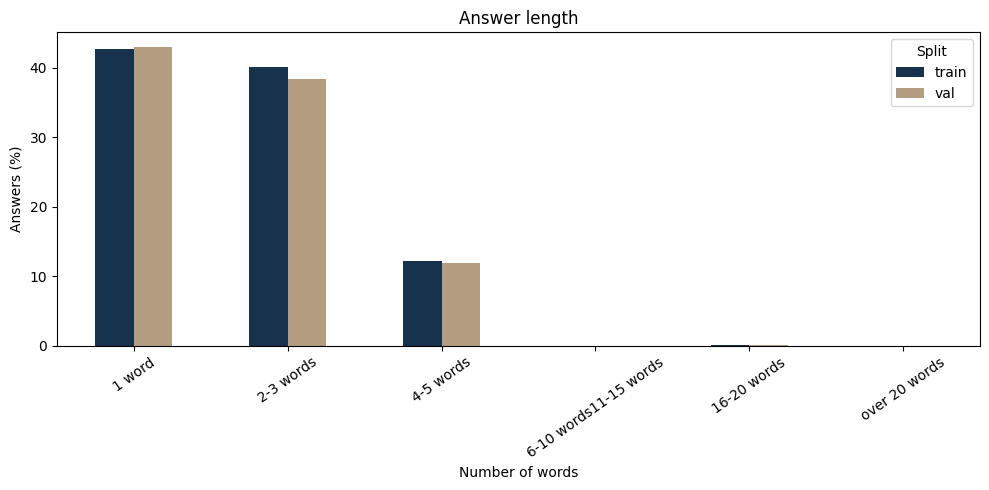

In [ ]:
length_order = ["1 word", "2-3 words", "4-5 words", "6-10 words"
                "11-15 words", "16-20 words", "over 20 words"]

answer_plot = answer_groups.pivot(
    index="length_group",
    columns="split",
    values="percent"
).reindex(length_order)

fig, ax = plt.subplots(figsize=(10, 5))
answer_plot[["train", "val"]].plot.bar(
    ax=ax,
    color=["#17324D", "#B29D80"],
)

ax.set_title("Answer length")
ax.set_xlabel("Number of words")
ax.set_ylabel("Answers (%)")
ax.legend(title="Split")
ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "answer_lengths.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## OCR Word Count

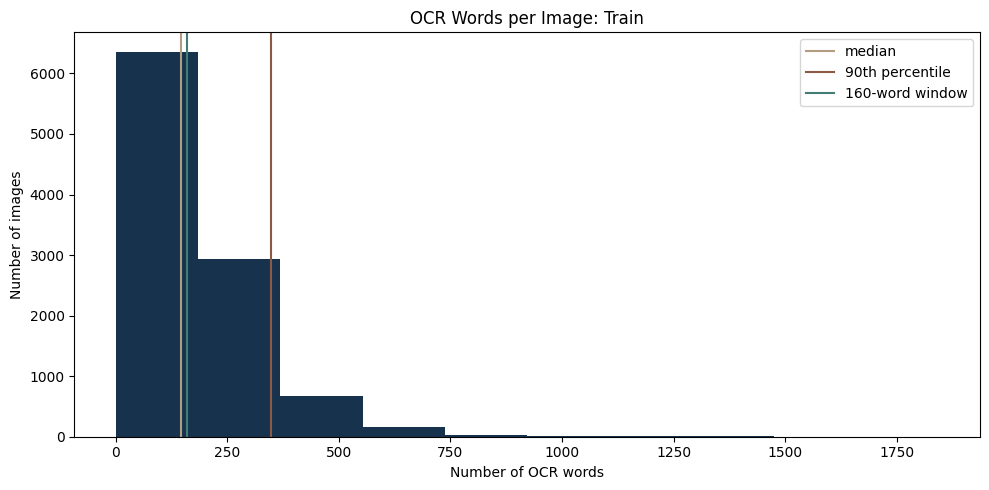

In [21]:
annotation_path = ROOT / "data/raw/annotations/train_v1.0_withQT.json"
with annotation_path.open("r", encoding="utf-8") as file:
    train_records = json.load(file)["data"]

train_images = { Path(record["image"]).stem.lower() for record in train_records }
ocr_index = { path.stem.lower(): path for path in (ROOT / "data/raw/ocr").rglob("*.json")}

ocr_word_counts = []
for image_name in sorted(train_images):
    ocr_path  = ocr_index.get(image_name)
    if ocr_path is None:
        continue

    try:
        words = load_ocr(ocr_path)["words"]
    except ValueError:
        words = []
    ocr_word_counts.append(len(words))

train_summary = ocr_summary.loc[ocr_summary["split"] == "train"].iloc[0]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(ocr_word_counts, color="#17324D")
ax.axvline(train_summary["median_words"], color="#B29D80", label="median")
ax.axvline(train_summary["p90_words"], color="#8A5A44", label="90th percentile")
ax.axvline(160, color="#427C73", label="160-word window")

ax.set_title("OCR Words per Image: Train")
ax.set_xlabel("Number of OCR words")
ax.set_ylabel("Number of images")
ax.legend()

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "ocr_word_counts.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## OCR Boxes

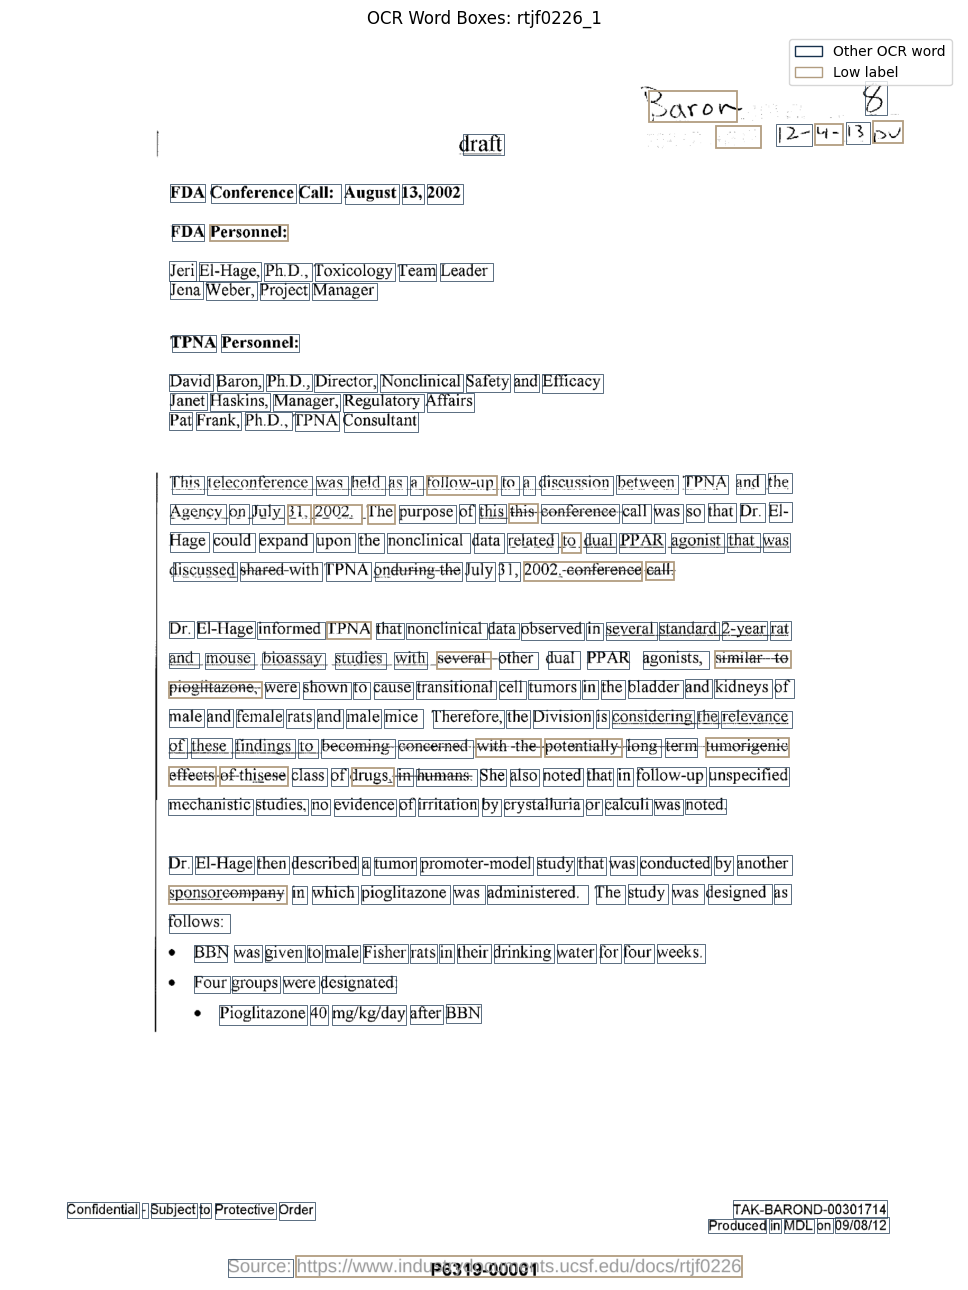

OCR words: 250
Low labels: 25


In [22]:
image_name = "rtjf0226_1"

image_path = ROOT / "data/raw/images" / f"{image_name}.png"
ocr_path = ROOT / "data/raw/ocr" / f"{image_name}.json"

with Image.open(image_path) as source:
    image = source.convert("RGB")

ocr = load_ocr(ocr_path)
words = ocr["words"]

scale_x = image.width / ocr["width"]
scale_y = image.height / ocr["height"]

fig, ax = plt.subplots(figsize=(10, 13))
ax.imshow(image)

low_count = 0
for word in words:
    is_low = str(word.get("confidence_label") or "").strip().lower() == "low"
    if is_low:
        low_count += 1

    x1, y1, x2, y2 = word["box"]

    x1 *= scale_x
    x2 *= scale_x
    y1 *= scale_y
    y2 *= scale_y

    box = Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="#B29D80" if is_low else "#17324D",
        linewidth=1.3 if is_low else 0.5
    )

    ax.add_patch(box)

ax.legend(handles=[
    Patch(facecolor="none", edgecolor="#17324D", label="Other OCR word"),
    Patch(facecolor="none", edgecolor="#B29D80", label="Low label")
    ], loc="upper right"
)

ax.set_title(f"OCR Word Boxes: {image_name}")
ax.axis("off")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "ocr_boxes.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("OCR words:", len(words))
print("Low labels:", low_count)

## Low Labels by Split

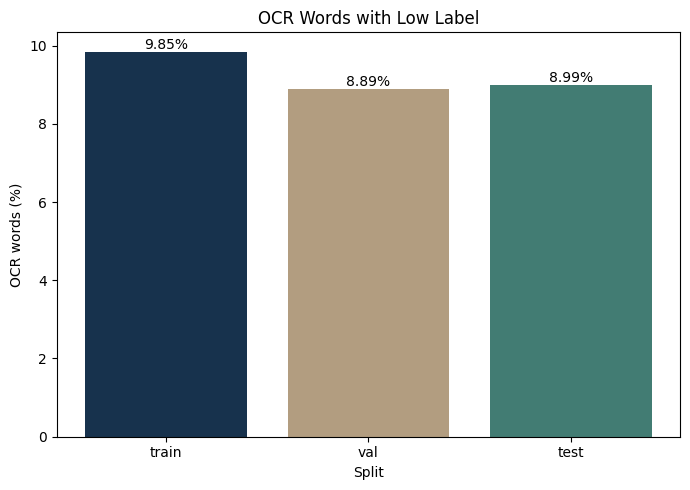

In [23]:
split_order = ["train", "val", "test"]
low_plot = ocr_summary.set_index("split").loc[split_order]

fig, ax = plt.subplots(figsize=(7,5))
bars = ax.bar(low_plot.index, low_plot["low_word_percent"], color=["#17324D", "#B29D80", "#427C73"])

ax.bar_label(bars, fmt="%.2f%%")
ax.set_title("OCR Words with Low Label")
ax.set_xlabel("Split")
ax.set_ylabel("OCR words (%)")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "low_labels.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## OCR Length by Split

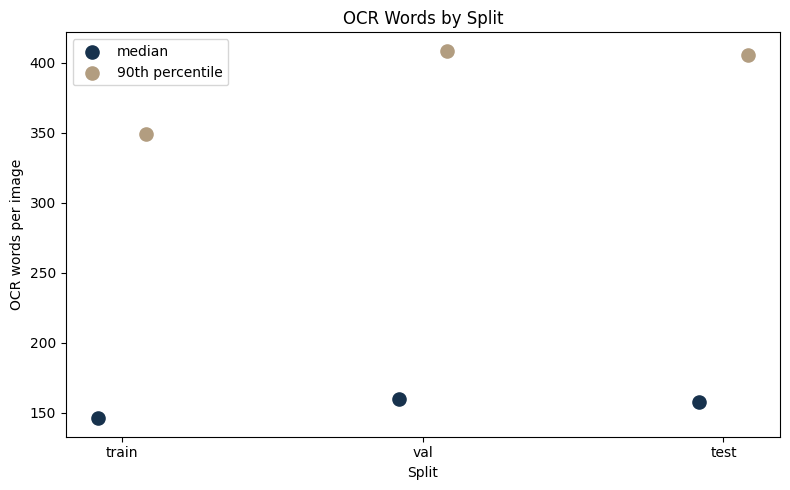

In [24]:
length_plot = ocr_summary.set_index("split").loc[split_order]

x = list(range(len(split_order)))
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    [value - 0.08 for value in x],
    length_plot["median_words"],
    color="#17324D",
    s=90,
    label="median"
)

ax.scatter(
    [value + 0.08 for value in x],
    length_plot["p90_words"],
    color="#B29D80",
    s=90,
    label="90th percentile",
)

ax.set_xticks(x, split_order)
ax.set_title("OCR Words by Split")
ax.set_xlabel("Split")
ax.set_ylabel("OCR words per image")
ax.legend()

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "ocr_length_by_split.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## Questions per Image

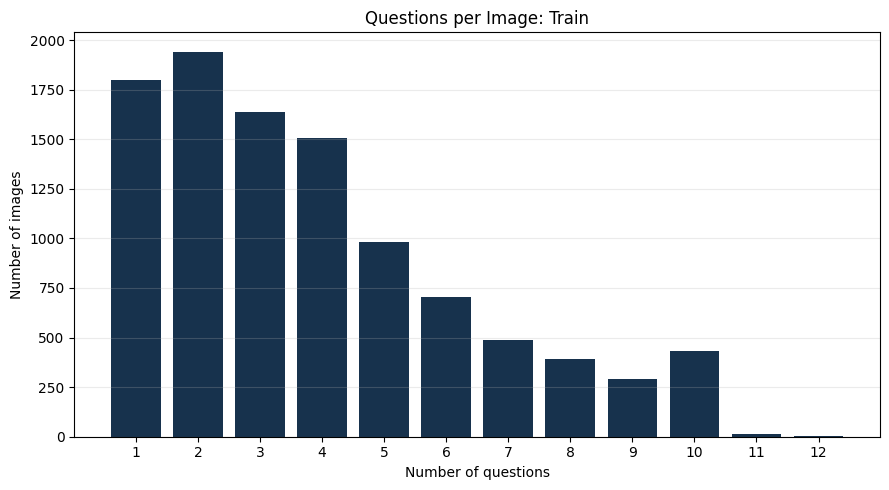

Images with more than one question: 8395
Percent: 82.35


In [ ]:
question_counts = pd.Series([Path(record["image"]).stem.lower() for record in train_records]).value_counts()
question_frequency = question_counts.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(question_frequency.index, question_frequency.values, color="#17324D")
ax.set_xticks(question_frequency.index)
ax.set_title("Questions per Image: Train")
ax.set_xlabel("Number of questions")
ax.set_ylabel("Number of images")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "questions_per_image.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Images with more than one question:", int((question_counts > 1).sum()))
print("Percent:", round((question_counts > 1).mean() * 100, 2))

## Window Estimate

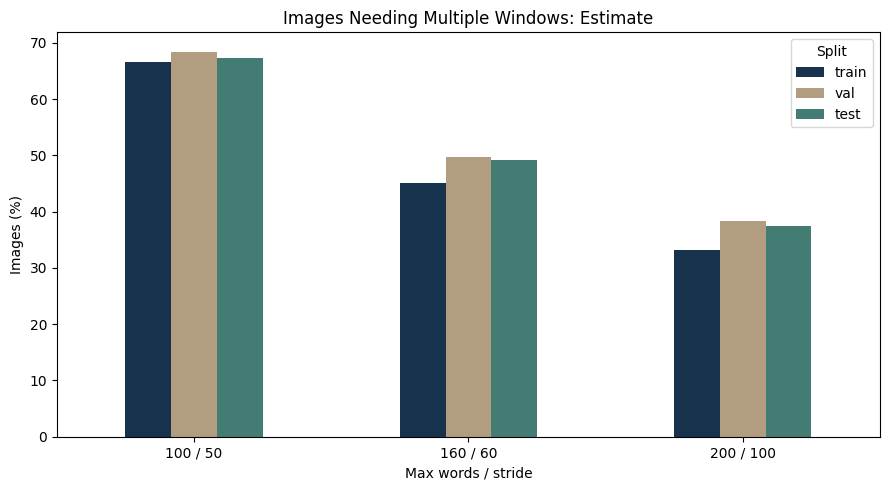

In [ ]:
window_data = pd.read_csv(EDA_DIR / "windows.csv")
document_count_by_split = ocr_summary.set_index("split")["documents"]

window_data["percent_multiple_windows"] = (
    window_data["documents_with_multiple_windows"] / window_data["split"].map(document_count_by_split)  * 100
)
window_data["setting"] = window_data["max_words"].astype(str) + " / " + window_data["stride"].astype(str)
setting_order = ["100 / 50", "160 / 60", "200 / 100"]

window_plot = window_data.pivot(
    index="setting",
    columns="split",
    values="percent_multiple_windows"
).reindex(setting_order)

fig, ax = plt.subplots(figsize=(9, 5))
window_plot[split_order].plot.bar(
    ax=ax,
    color=["#17324D", "#B29D80", "#427C73"],
)

ax.set_title("Images Needing Multiple Windows: Estimate")
ax.set_xlabel("Max words / stride")
ax.set_ylabel("Images (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Split")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "window_estimate.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()